# Aula 15: Aproximação Polinomial: Método dos Mínimos Quadrados

## Ideia

Diferentemente da interpolação, a função ajustada **não precisa passar por todos os pontos**. Procuramos uma função que represente a tendência dos dados.

## Caso discreto

Dados $(x_k,y_k)$, $k=1,\ldots,m$, escolhemos funções $g_j(x)$ e ajustamos

$$\varphi(x)=\alpha_1g_1(x)+\cdots+\alpha_ng_n(x).$$

O desvio no ponto $k$ é $d_k=y_k-\varphi(x_k)$. Minimizamos a soma dos quadrados:

$$F(\alpha_1,\ldots,\alpha_n)=\sum_{k=1}^{m}[y_k-\varphi(x_k)]^2.$$

Exemplos de modelos: reta $\varphi(x)=a+bx$; parábola $\varphi(x)=a+bx+cx^2$.

## Equações normais: Ajuste linear

Para $\varphi(x)=a+bx$, as equações normais são

$$\begin{cases}ma+b\sum x_k=\sum y_k,\\a\sum x_k+b\sum x_k^2=\sum x_ky_k.\end{cases}$$

Assim,

$$b=\frac{m\sum x_ky_k-(\sum x_k)(\sum y_k)}{m\sum x_k^2-(\sum x_k)^2},\qquad a=\frac{\sum y_k-b\sum x_k}{m}.$$

Os coeficientes $a$ e $b$ definem a reta ajustada.

## Algoritmo: Ajuste Linear 

```text
Entrada:
    x: vetor com m valores conhecidos
    y: vetor com m valores correspondentes

sx = 0
sy = 0
sx2 = 0
sxy = 0
Para k de 0 até m-1 faça
    sx = sx + x[k]
    sy = sy + y[k]
    sx2 = sx2 + x[k] * x[k]
    sxy = sxy + x[k] * y[k]
Fim-Para
b = (m * sxy - sx * sy) / (m * sx2 - sx * sx)
a = (sy - b * sx) / m
Retorne a, b
```

Pressupõe pelo menos dois valores distintos de $x$.

In [1]:
def ajuste_linear(x, y):
    m = len(x)
    sx = 0
    sy = 0
    sx2 = 0
    sxy = 0
    for k in range(m):
        sx = sx + x[k]
        sy = sy + y[k]
        sx2 = sx2 + x[k] * x[k]
        sxy = sxy + x[k] * y[k]
    b = (m * sxy - sx * sy) / (m * sx2 - sx * sx)
    a = (sy - b * sx) / m
    return a, b

In [2]:
import numpy as np
import matplotlib.pyplot as plt

def grafico_ajuste(x, y, funcao, titulo):
    t = np.linspace(min(x), max(x), 200)
    plt.scatter(x, y, label="Dados")
    plt.plot(t, funcao(t), label="Ajuste")
    plt.title(titulo)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.grid(True)
    plt.legend()
    plt.show()

## Exemplo 1: Ajuste linear 

Considere os pontos:

| $x$ | 1 | 2 | 3 | 4 | 5 |
|---|---:|---:|---:|---:|---:|
| $y$ | 2 | 4 | 5 | 4 | 6 |

As somatórias são $m=5$, $\sum x_k=15$, $\sum y_k=21$, $\sum x_k^2=55$ e $\sum x_ky_k=71$.

As equações normais ficam:

$$\begin{cases}5a+15b=21,\\15a+55b=71.\end{cases}$$

Logo, $a=1,8$, $b=0,8$ e **$\varphi(x)=1,8+0,8x$**.

a = 1.8000, b = 0.8000
Reta ajustada: φ(x) = 1.8000 + 0.8000x
Desvios: [-0.6, 0.6, 0.8, -1.0, 0.2]
Soma dos quadrados dos desvios: F = 2.4000


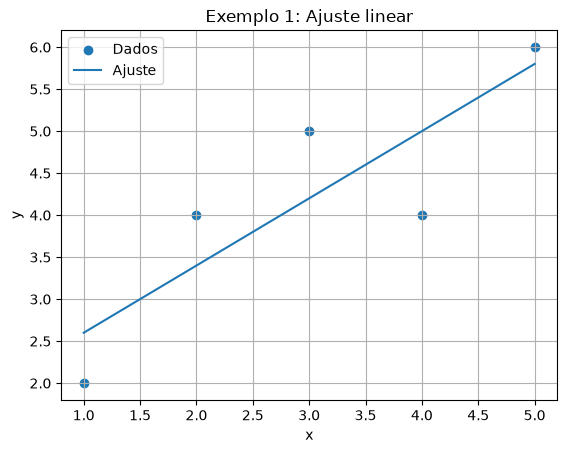

In [3]:
x1 = [1, 2, 3, 4, 5]
y1 = [2, 4, 5, 4, 6]
a, b = ajuste_linear(x1, y1)
phi1 = lambda x: a + b * x
residuos = [y1[k] - phi1(x1[k]) for k in range(len(x1))]
F = sum(d**2 for d in residuos)
print(f"a = {a:.4f}, b = {b:.4f}")
print(f"Reta ajustada: φ(x) = {a:.4f} + {b:.4f}x")
print("Desvios:", [round(d, 4) for d in residuos])
print(f"Soma dos quadrados dos desvios: F = {F:.4f}")
grafico_ajuste(x1, y1, phi1, "Exemplo 1: Ajuste linear")

## Equações normais: Caso geral

Para $\varphi(x)=\sum_{j=1}^n\alpha_jg_j(x)$, construímos a matriz

$$G_{kj}=g_j(x_k).$$

As equações normais são

$$\boxed{(G^TG)\alpha=G^Ty}.$$

Resolvemos esse sistema linear para encontrar os coeficientes. Para o modelo $\varphi(x)=ax^2$, há apenas um coeficiente:

$$\boxed{a=\frac{\sum x_k^2y_k}{\sum x_k^4}}.$$

## Exemplo 2: Ajuste da função $\varphi(x)=ax^2$ 

| $x$ | -1,0 | -0,75 | -0,6 | -0,5 | -0,3 | 0 | 0,2 | 0,4 | 0,5 | 0,7 | 1,0 |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| $f(x)$ | 2,05 | 1,153 | 0,45 | 0,4 | 0,5 | 0 | 0,2 | 0,6 | 0,512 | 1,2 | 2,05 |

Como os pontos sugerem uma parábola com vértice próximo da origem, escolhemos $\varphi(x)=ax^2$.

$$F(a)=\sum_k(y_k-ax_k^2)^2,\qquad a=\frac{\sum_kx_k^2y_k}{\sum_kx_k^4}.$$

Σx²y = 5.875562; Σx⁴ = 2.846406
φ(x) = 2.064204x²
F = 0.320695


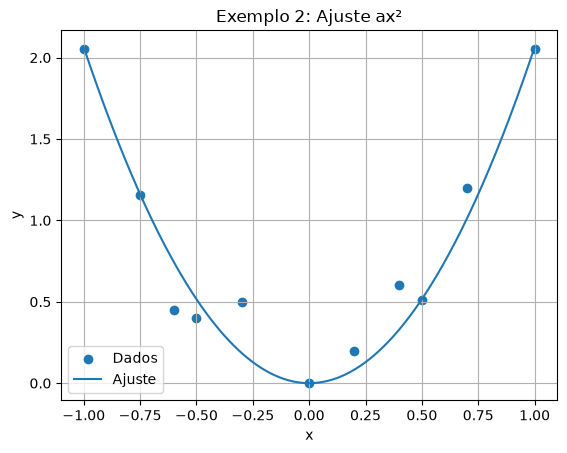

In [4]:
x2 = [-1.0, -0.75, -0.6, -0.5, -0.3, 0, 0.2, 0.4, 0.5, 0.7, 1.0]
y2 = [2.05, 1.153, 0.45, 0.4, 0.5, 0, 0.2, 0.6, 0.512, 1.2, 2.05]
sx2y = sum(x2[k]**2 * y2[k] for k in range(len(x2)))
sx4 = sum(xk**4 for xk in x2)
a2 = sx2y / sx4
phi2 = lambda x: a2 * x**2
F2 = sum((y2[k] - phi2(x2[k]))**2 for k in range(len(x2)))
print(f"Σx²y = {sx2y:.6f}; Σx⁴ = {sx4:.6f}")
print(f"φ(x) = {a2:.6f}x²")
print(f"F = {F2:.6f}")
grafico_ajuste(x2, y2, phi2, "Exemplo 2: Ajuste ax²")

## Exercício 1: Ajuste linear 

Ajuste uma reta $\varphi(x)=a+bx$ aos dados e calcule a soma dos quadrados dos desvios.

| $x$ | 0 | 1 | 2 | 3 |
|---|---:|---:|---:|---:|
| $y$ | 1 | 2 | 2 | 4 |

φ(x) = 0.9000 + 0.9000x
F = 0.7000


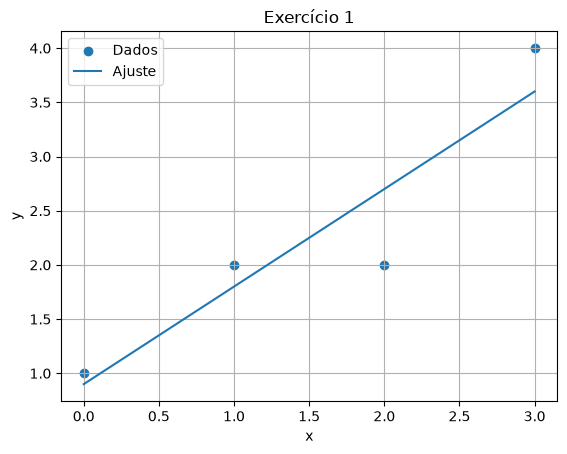

In [5]:
x_ex1 = [0, 1, 2, 3]
y_ex1 = [1, 2, 2, 4]
a_ex1, b_ex1 = ajuste_linear(x_ex1, y_ex1)
phi_ex1 = lambda x: a_ex1 + b_ex1*x
F_ex1 = sum((y_ex1[k] - phi_ex1(x_ex1[k]))**2 for k in range(len(x_ex1)))
print(f"φ(x) = {a_ex1:.4f} + {b_ex1:.4f}x")
print(f"F = {F_ex1:.4f}")
grafico_ajuste(x_ex1, y_ex1, phi_ex1, "Exercício 1")

## Exercício 2: Ajuste quadrático 

Ajuste uma parábola $\varphi(x)=a+bx+cx^2$ aos dados, utilizando as equações normais, e calcule a soma dos quadrados dos desvios.

| $x$ | -2 | -1 | 0 | 1 | 2 |
|---|---:|---:|---:|---:|---:|
| $y$ | 8 | 2 | 0 | 3 | 9 |

φ(x) = 0.2571 + 0.3000x + 2.0714x²
F = 0.2286


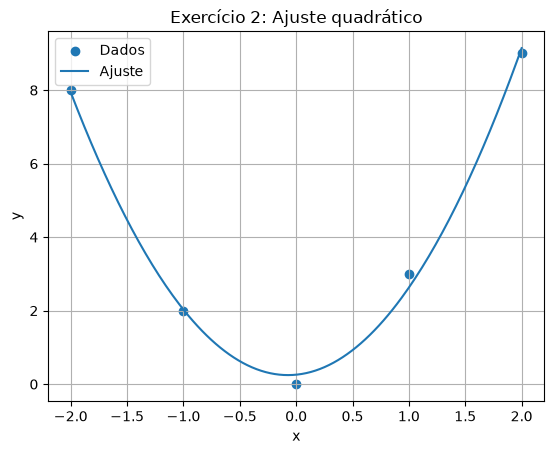

In [6]:
x_ex2 = np.array([-2, -1, 0, 1, 2], dtype=float)
y_ex2 = np.array([8, 2, 0, 3, 9], dtype=float)
G = np.column_stack([np.ones(len(x_ex2)), x_ex2, x_ex2**2])
coef = np.linalg.solve(G.T @ G, G.T @ y_ex2)
a_ex2, b_ex2, c_ex2 = coef
phi_ex2 = lambda x: a_ex2 + b_ex2*x + c_ex2*x**2
F_ex2 = sum((y_ex2 - phi_ex2(x_ex2))**2)
print(f"φ(x) = {a_ex2:.4f} + {b_ex2:.4f}x + {c_ex2:.4f}x²")
print(f"F = {F_ex2:.4f}")
grafico_ajuste(x_ex2, y_ex2, phi_ex2, "Exercício 2: Ajuste quadrático")